In [3]:
  !nvidia-smi


Thu Nov  5 10:58:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             14W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
!unzip -q "/content/drive/MyDrive/Colab Notebooks/archive.zip" -d /content/data

In [9]:
import os

# find the folder that contains train/ and test/
for root, dirs, files in os.walk("/content/data"):
    if "train" in dirs and "test" in dirs:
        DATA_DIR = root
        break

print("Data folder:", DATA_DIR)
print("Contents:", os.listdir(DATA_DIR))

# count images in each folder
for split in ["train", "val", "test"]:
    for cls in ["NORMAL", "PNEUMONIA"]:
        path = os.path.join(DATA_DIR, split, cls)
        if os.path.exists(path):
            print(split, cls, len(os.listdir(path)))

Data folder: /content/data/chest_xray
Contents: ['train', 'test', 'chest_xray', 'val', '__MACOSX']
train NORMAL 1341
train PNEUMONIA 3875
val NORMAL 8
val PNEUMONIA 8
test NORMAL 234
test PNEUMONIA 390


In [10]:
import os, random, numpy as np, torch, torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from sklearn.metrics import roc_auc_score, recall_score

torch.manual_seed(42); random.seed(42); np.random.seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tfm = transforms.Compose([
    transforms.Grayscale(3), transforms.Resize((224, 224)),
    transforms.RandomRotation(10), transforms.ToTensor(),
    transforms.Normalize(mean, std)])

eval_tfm = transforms.Compose([   # no random changes for validation/test
    transforms.Grayscale(3), transforms.Resize((224, 224)),
    transforms.ToTensor(), transforms.Normalize(mean, std)])

train_dir = os.path.join(DATA_DIR, "train")
full_train = datasets.ImageFolder(train_dir, transform=train_tfm)
full_eval  = datasets.ImageFolder(train_dir, transform=eval_tfm)
print("Classes:", full_train.class_to_idx)   # NORMAL=0, PNEUMONIA=1

idx = list(range(len(full_train)))
random.shuffle(idx)
n_val = int(0.15 * len(idx))
val_idx, train_idx = idx[:n_val], idx[n_val:]

train_loader = DataLoader(Subset(full_train, train_idx), batch_size=32, shuffle=True, num_workers=2)
val_loader   = DataLoader(Subset(full_eval, val_idx), batch_size=32, shuffle=False, num_workers=2)
print("Train images:", len(train_idx), "| Validation images:", len(val_idx))

Using: cuda
Classes: {'NORMAL': 0, 'PNEUMONIA': 1}
Train images: 4434 | Validation images: 782


In [11]:
model = models.densenet121(weights="IMAGENET1K_V1")
model.classifier = nn.Linear(model.classifier.in_features, 2)
model = model.to(device)

labels = [full_train.targets[i] for i in train_idx]
counts = np.bincount(labels)
weights = torch.tensor(len(labels) / (2 * counts), dtype=torch.float).to(device)
print("Class weights:", weights)

criterion = nn.CrossEntropyLoss(weight=weights)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 89.8MB/s]


Class weights: tensor([1.9637, 0.6708], device='cuda:0')


In [12]:
EPOCHS = 10
SAVE_PATH = "/content/drive/MyDrive/medxray/model.pt"
os.makedirs(os.path.dirname(SAVE_PATH), exist_ok=True)
best_auc = 0

for epoch in range(EPOCHS):
    # --- learn ---
    model.train()
    total_loss = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)

    # --- check on validation images ---
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for x, y in val_loader:
            p = torch.softmax(model(x.to(device)), dim=1)[:, 1].cpu().numpy()
            probs += list(p); ys += y.tolist()
    preds = [int(p > 0.5) for p in probs]
    acc = np.mean(np.array(preds) == np.array(ys))
    auc = roc_auc_score(ys, probs)
    rec = recall_score(ys, preds)

    print(f"Epoch {epoch+1}/{EPOCHS} | loss {total_loss/len(train_idx):.4f} | "
          f"val acc {acc:.3f} | val AUC {auc:.3f} | val recall {rec:.3f}")

    if auc > best_auc:
        best_auc = auc
        torch.save(model.state_dict(), SAVE_PATH)
        print("  -> saved best model")

Epoch 1/10 | loss 0.1371 | val acc 0.976 | val AUC 0.998 | val recall 0.974
  -> saved best model
Epoch 2/10 | loss 0.0535 | val acc 0.981 | val AUC 0.997 | val recall 0.982
Epoch 3/10 | loss 0.0457 | val acc 0.960 | val AUC 0.998 | val recall 0.947
Epoch 4/10 | loss 0.0296 | val acc 0.968 | val AUC 0.999 | val recall 0.958
  -> saved best model
Epoch 5/10 | loss 0.0209 | val acc 0.981 | val AUC 0.998 | val recall 0.975
Epoch 6/10 | loss 0.0174 | val acc 0.986 | val AUC 0.999 | val recall 0.989
Epoch 7/10 | loss 0.0180 | val acc 0.980 | val AUC 0.998 | val recall 0.977
Epoch 8/10 | loss 0.0158 | val acc 0.968 | val AUC 0.998 | val recall 0.958
Epoch 9/10 | loss 0.0189 | val acc 0.983 | val AUC 0.999 | val recall 0.979
Epoch 10/10 | loss 0.0120 | val acc 0.985 | val AUC 0.998 | val recall 0.984


In [13]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt

model.load_state_dict(torch.load(SAVE_PATH, map_location=device))
model.eval()

test_set = datasets.ImageFolder(os.path.join(DATA_DIR, "test"), transform=eval_tfm)
test_loader = DataLoader(test_set, batch_size=32, shuffle=False, num_workers=2)

probs, ys = [], []
with torch.no_grad():
    for x, y in test_loader:
        p = torch.softmax(model(x.to(device)), dim=1)[:, 1].cpu().numpy()
        probs += list(p); ys += y.tolist()

probs, ys = np.array(probs), np.array(ys)
preds = (probs > 0.5).astype(int)

print(classification_report(ys, preds, target_names=["NORMAL", "PNEUMONIA"], digits=3))
print("AUC:", round(roc_auc_score(ys, probs), 4))
cm = confusion_matrix(ys, preds)
print("Confusion matrix:\n", cm)

              precision    recall  f1-score   support

      NORMAL      0.984     0.778     0.869       234
   PNEUMONIA      0.882     0.992     0.934       390

    accuracy                          0.912       624
   macro avg      0.933     0.885     0.901       624
weighted avg      0.920     0.912     0.909       624

AUC: 0.9746
Confusion matrix:
 [[182  52]
 [  3 387]]


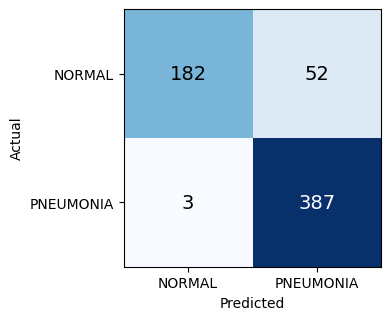

In [14]:
ASSETS = "/content/drive/MyDrive/medxray/assets"
os.makedirs(ASSETS, exist_ok=True)

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["NORMAL", "PNEUMONIA"]); ax.set_yticklabels(["NORMAL", "PNEUMONIA"])
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
plt.tight_layout()
plt.savefig(f"{ASSETS}/confusion_matrix.png", dpi=150)
plt.show()

Total wrong predictions: 55


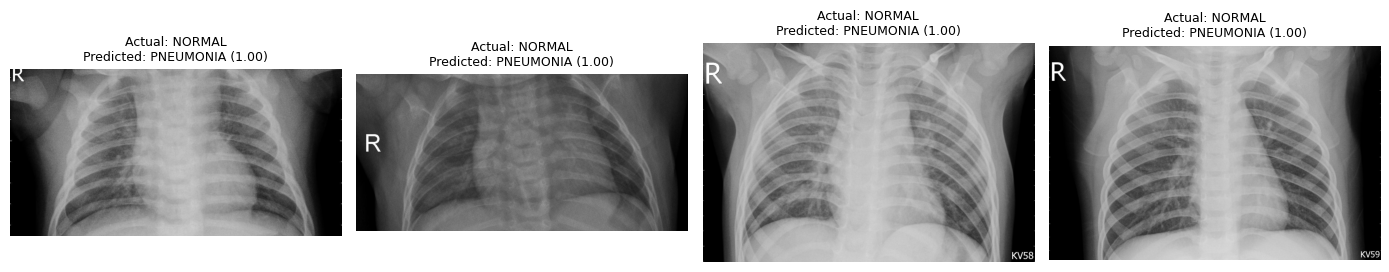

In [15]:
wrong = np.where(preds != ys)[0]
wrong = wrong[np.argsort(-np.abs(probs[wrong] - 0.5))]   # most confident errors first
print("Total wrong predictions:", len(wrong))

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, i in zip(axes, wrong[:4]):
    path, _ = test_set.samples[i]
    ax.imshow(plt.imread(path), cmap="gray")
    ax.set_title(f"Actual: {test_set.classes[ys[i]]}\nPredicted: {test_set.classes[preds[i]]} ({probs[i]:.2f})", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig(f"{ASSETS}/failure_cases.png", dpi=150)
plt.show()

In [16]:
!pip install -q grad-cam

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from PIL import Image

model.eval()
cam = GradCAM(model=model, target_layers=[model.features[-1]])

def heatmap_for(path):
    pil = Image.open(path)
    rgb = np.array(pil.convert("RGB").resize((224, 224))).astype(np.float32) / 255.0
    x = eval_tfm(pil).unsqueeze(0).to(device)
    with torch.no_grad():
        prob = torch.softmax(model(x), dim=1)[0, 1].item()
    pred = int(prob > 0.5)
    heat = cam(input_tensor=x, targets=[ClassifierOutputTarget(pred)])[0]
    overlay = show_cam_on_image(rgb, heat, use_rgb=True)
    return overlay, pred, prob

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


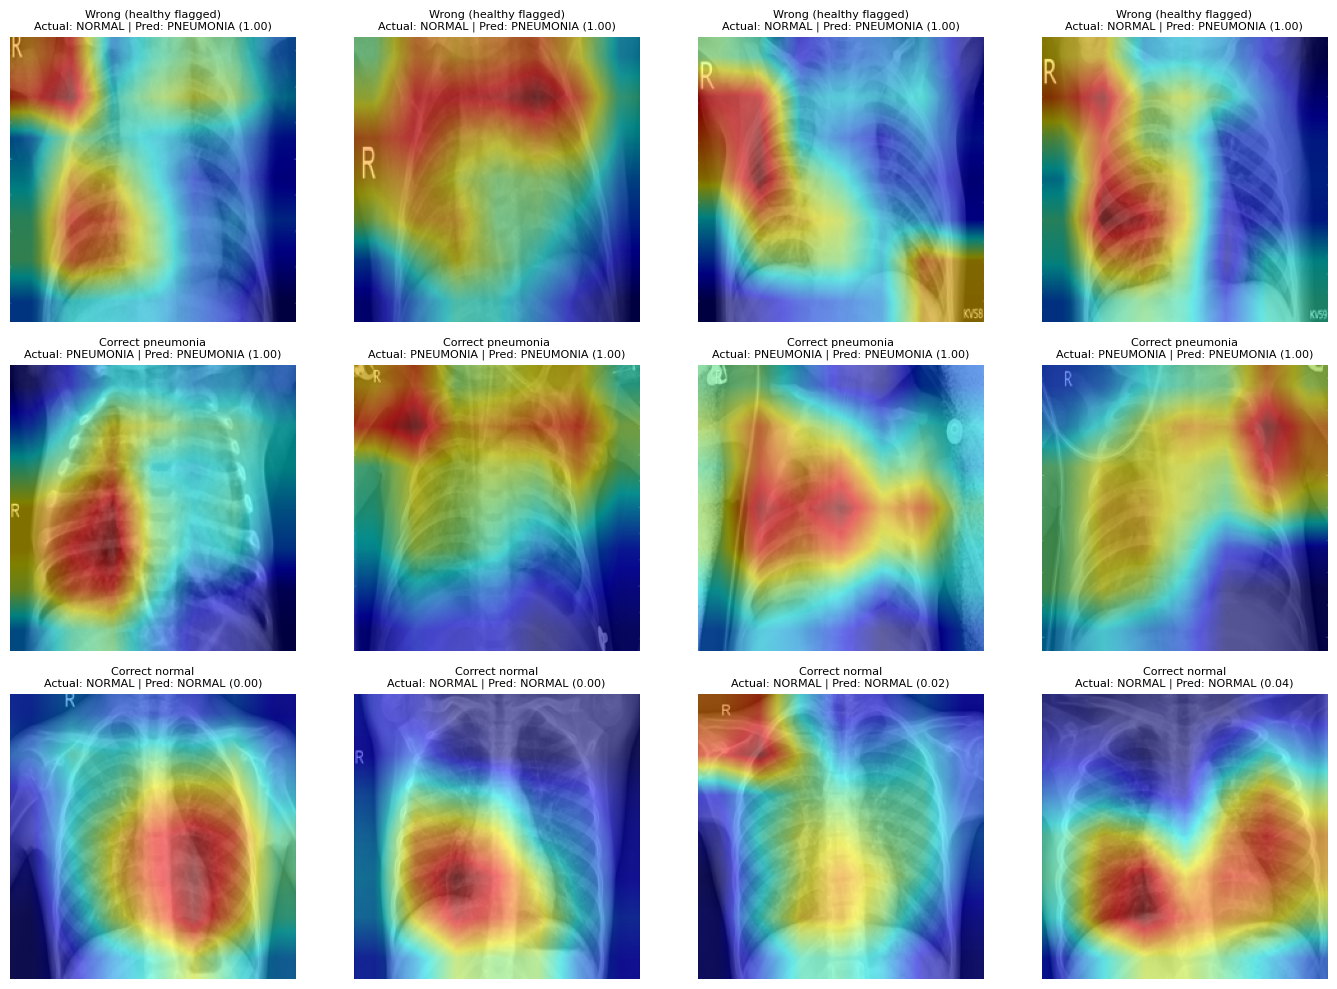

In [17]:
correct_pneu   = [i for i in range(len(ys)) if ys[i] == 1 and preds[i] == 1][:4]
correct_normal = [i for i in range(len(ys)) if ys[i] == 0 and preds[i] == 0][:4]
groups = [("Wrong (healthy flagged)", list(wrong[:4])),
          ("Correct pneumonia", correct_pneu),
          ("Correct normal", correct_normal)]

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for r, (name, ids) in enumerate(groups):
    for c, i in enumerate(ids):
        path, _ = test_set.samples[i]
        overlay, pred, prob = heatmap_for(path)
        axes[r, c].imshow(overlay)
        axes[r, c].set_title(f"{name}\nActual: {test_set.classes[ys[i]]} | Pred: {test_set.classes[pred]} ({prob:.2f})", fontsize=8)
        axes[r, c].axis("off")
plt.tight_layout()
plt.savefig(f"{ASSETS}/gradcam_examples.png", dpi=150)
plt.show()

In [18]:
train_tfm2 = transforms.Compose([
    transforms.Grayscale(3), transforms.Resize((256, 256)), transforms.CenterCrop(224),
    transforms.RandomRotation(10), transforms.ToTensor(),
    transforms.Normalize(mean, std),
    transforms.RandomErasing(p=0.5, scale=(0.02, 0.1))])

eval_tfm2 = transforms.Compose([
    transforms.Grayscale(3), transforms.Resize((256, 256)), transforms.CenterCrop(224),
    transforms.ToTensor(), transforms.Normalize(mean, std)])

ds_train2 = datasets.ImageFolder(train_dir, transform=train_tfm2)
ds_eval2  = datasets.ImageFolder(train_dir, transform=eval_tfm2)
train_loader2 = DataLoader(Subset(ds_train2, train_idx), batch_size=32, shuffle=True, num_workers=2)
val_loader2   = DataLoader(Subset(ds_eval2, val_idx), batch_size=32, shuffle=False, num_workers=2)

model2 = models.densenet121(weights="IMAGENET1K_V1")
model2.classifier = nn.Linear(model2.classifier.in_features, 2)
model2 = model2.to(device)
criterion2 = nn.CrossEntropyLoss(weight=weights)
optimizer2 = torch.optim.Adam(model2.parameters(), lr=1e-4)
SAVE_PATH2 = "/content/drive/MyDrive/medxray/model_v2.pt"

In [19]:
best_auc2 = 0
for epoch in range(10):
    model2.train()
    for x, y in train_loader2:
        x, y = x.to(device), y.to(device)
        optimizer2.zero_grad()
        criterion2(model2(x), y).backward()
        optimizer2.step()

    model2.eval()
    probs_v, ys_v = [], []
    with torch.no_grad():
        for x, y in val_loader2:
            p = torch.softmax(model2(x.to(device)), dim=1)[:, 1].cpu().numpy()
            probs_v += list(p); ys_v += y.tolist()
    auc = roc_auc_score(ys_v, probs_v)
    print(f"Epoch {epoch+1}/10 | val AUC {auc:.3f}")
    if auc > best_auc2:
        best_auc2 = auc
        torch.save(model2.state_dict(), SAVE_PATH2)
        print("  -> saved best model")

Epoch 1/10 | val AUC 0.996
  -> saved best model
Epoch 2/10 | val AUC 0.997
  -> saved best model
Epoch 3/10 | val AUC 0.998
  -> saved best model
Epoch 4/10 | val AUC 0.998
  -> saved best model
Epoch 5/10 | val AUC 0.997
Epoch 6/10 | val AUC 0.998
  -> saved best model
Epoch 7/10 | val AUC 0.998
Epoch 8/10 | val AUC 0.998
  -> saved best model
Epoch 9/10 | val AUC 0.997
Epoch 10/10 | val AUC 0.998


In [20]:
model2.load_state_dict(torch.load(SAVE_PATH2, map_location=device))
model2.eval()

test_set2 = datasets.ImageFolder(os.path.join(DATA_DIR, "test"), transform=eval_tfm2)
test_loader2 = DataLoader(test_set2, batch_size=32, shuffle=False, num_workers=2)

probs2, ys2 = [], []
with torch.no_grad():
    for x, y in test_loader2:
        p = torch.softmax(model2(x.to(device)), dim=1)[:, 1].cpu().numpy()
        probs2 += list(p); ys2 += y.tolist()

probs2, ys2 = np.array(probs2), np.array(ys2)
preds2 = (probs2 > 0.5).astype(int)
print(classification_report(ys2, preds2, target_names=["NORMAL", "PNEUMONIA"], digits=3))
print("AUC:", round(roc_auc_score(ys2, probs2), 4))
print("Confusion matrix:\n", confusion_matrix(ys2, preds2))

              precision    recall  f1-score   support

      NORMAL      0.976     0.692     0.810       234
   PNEUMONIA      0.843     0.990     0.910       390

    accuracy                          0.878       624
   macro avg      0.909     0.841     0.860       624
weighted avg      0.893     0.878     0.873       624

AUC: 0.9714
Confusion matrix:
 [[162  72]
 [  4 386]]


In [24]:
from google.colab import drive
drive.mount('/content/drive')

import torch, torch.nn as nn
from torchvision import models, transforms
from PIL import Image
from pathlib import Path

model = models.densenet121(weights=None)
model.classifier = nn.Linear(model.classifier.in_features, 2)
model.load_state_dict(torch.load("/content/drive/MyDrive/medxray/model.pt", map_location="cpu"))
model.eval()

tfm = transforms.Compose([
    transforms.Grayscale(3), transforms.Resize((224, 224)),
    transforms.ToTensor(), transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

for p in sorted(Path("/content/drive/MyDrive/medxray/samples").rglob("*")):
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
        with torch.no_grad():
            prob = torch.softmax(model(tfm(Image.open(p)).unsqueeze(0)), dim=1)[0, 1].item()
        print(f"{p.name:40} p(pneumonia) = {prob:.3f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
IM-0001-0001.jpeg                        p(pneumonia) = 0.001
IM-0003-0001.jpeg                        p(pneumonia) = 0.002
IM-0005-0001.jpeg                        p(pneumonia) = 0.018
person100_bacteria_475.jpeg              p(pneumonia) = 0.999
person100_bacteria_477.jpeg              p(pneumonia) = 1.000
person100_bacteria_478.jpeg              p(pneumonia) = 1.000


In [22]:
from pathlib import Path

base = Path("/content/drive/MyDrive/medxray")
print("medxray folder contains:", [p.name for p in base.iterdir()])

samples = base / "samples"
print("samples exists:", samples.exists())
if samples.exists():
    files = [p for p in samples.rglob("*") if p.is_file()]
    print("files found:", len(files))
    for p in files[:10]:
        print("  ", p.relative_to(base))


medxray folder contains: ['model.pt', 'assets', 'model_v2.pt']
samples exists: False


In [23]:
import os, shutil
from pathlib import Path

# Unzip the dataset again if Colab was reset
if not os.path.exists("/content/data/chest_xray/test"):
    !unzip -q "/content/drive/MyDrive/Colab Notebooks/archive.zip" -d /content/data

test_dir = Path("/content/data/chest_xray/test")
samples = Path("/content/drive/MyDrive/medxray/samples")

for cls in ["NORMAL", "PNEUMONIA"]:
    (samples / cls).mkdir(parents=True, exist_ok=True)
    for p in sorted((test_dir / cls).glob("*.jpeg"))[:3]:   # 3 images per class
        shutil.copy(p, samples / cls / p.name)

print("Copied:", sorted(str(p.relative_to(samples)) for p in samples.rglob("*.jpeg")))

Copied: ['NORMAL/IM-0001-0001.jpeg', 'NORMAL/IM-0003-0001.jpeg', 'NORMAL/IM-0005-0001.jpeg', 'PNEUMONIA/person100_bacteria_475.jpeg', 'PNEUMONIA/person100_bacteria_477.jpeg', 'PNEUMONIA/person100_bacteria_478.jpeg']
